# Explore StormCrews without writing code

[![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/abrahambohorquez/stormcrews/main?labpath=notebooks%2Fexplore.ipynb)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abrahambohorquez/stormcrews/blob/main/notebooks/explore.ipynb)

StormCrews replays real storms that hit the power distribution grids of New England (39 storms) and of Pennsylvania
and West Virginia (46 storms) between 2018 and 2025, hour by hour and county by county, and simulates the repair crews
that bring customers back. This notebook puts its main settings on sliders and menus. Run the cells from the top
(menu *Run > Run All Cells*, or Shift+Enter on each cell). The first run takes a few seconds; after that, every change
reruns the storm and redraws the results.

Every number on the screen comes from one simulation of the storm with the settings shown. Nothing is precomputed.

## The three tabs

* **Real storm.** One of the 85 storms, with every setting below. Pin a run as the baseline and change any setting to
  see the difference.
* **Synthetic storm.** A storm that never happened. You place a gust field on the map, and the damage it would cause
  comes from the damage model fitted on all storms. Its timing and crews are borrowed from a real template storm.
* **Two rules.** Two restoration rules on the same storm with the same random draws, so the difference between them
  comes from the rules alone.

## The controls

**Storm, calibration and rule**

| Control | What it does |
|---|---|
| Storm | The storm to replay: region (NE for New England, PA-WV for Pennsylvania and West Virginia), start date and name. Tropical Storm Isaias (August 2020) is the default. |
| Calibration | How the crews of each storm were fitted to the observed restoration. *shape* matches the observed customer-hours and the shape of the restoration curve; *equal* uses equal jobs of 35 customers and 3 h repairs; *anchored* sets the fleet from the line crews per customer out that utilities reported in public filings; *anchored_low* and *anchored_high* use the lowest and highest reported ratio (six PA-WV storms have no *anchored_low* fit). |
| Rule | How crews are spread over counties and when mutual aid is requested. *current practice* sends crews where customers are out and requests aid when 1 % of the region is out. *forecast weighted* also counts what the damage forecast still expects in each county. The *early aid* rules request 1.5 times the usual aid 24 h before the regional peak (with a perfect or a 12-hour-error forecast of the peak). |
| Seed | The random draw of job sizes, repair times and automatic restorations. The same seed gives the same run. |

**Weather and network what-if.** These change the real storm through the damage model. At their neutral values the
storm is replayed exactly, and the observed EAGLE-I curve is shown for comparison. Once any of them moves, the storm is
no longer the one that was observed, so the observed curve is hidden.

| Control | Unit | Neutral | What it does |
|---|---|---|---|
| Gust change | m/s | 0 | Added to the peak gust of every county. Damage grows faster above 20 m/s. |
| Rain factor | times | 1 | Multiplies the storm's accumulated precipitation. |
| Soil moisture change | m³/m³ | 0 | Added to the mean soil moisture. In the fitted model, wetter soil goes with more damage. |
| Footprint east, north | km | 0 | Moves the damage pattern of the storm across the map. |
| Footprint scale | times | 1 | Above 1 spreads the damage over a wider area, below 1 concentrates it. |
| Duration factor | times | 1 | Above 1 makes the damage arrive more slowly. |
| Automatic share | share | measured | Share of customers restored within the hour without a crew (reclosers, remote switching). Untick *keep the measured share* to set it. |

**Crews and operations**

| Control | Unit | Default | What it does |
|---|---|---|---|
| Fleet factor | times | 1 | Scales the calibrated local fleet of line crews. |
| Mutual aid | | normal | *normal*: requested aid arrives in full. *none*: nobody comes. |
| Aid lead time | h | 24 | Hours from the aid request to the crews' arrival. |
| Aid size | crews per local crew | 0.5 | Size of the usual mutual-aid request. |
| Job order | | largest | Which job of a county goes first: the one with most customers, the oldest, the largest unless a job has waited 48 h (*guard*), or the largest with one crew in ten always taking the oldest job (*sweep*). |
| Decision interval | h | 6 | Hours between the rule's decisions on where crews go. |

**Buttons.** *Run* reruns the storm (needed only when *Run on every change* is off). *Pin as baseline* keeps the
current run; it is drawn as a gray dashed curve and the metrics card shows the change against it. *Clear baseline*
drops it.

## The outputs

* **Restoration curve.** Customers out in the region at the end of every hour, in thousands. Red is what EAGLE-I
  recorded (real storms only), navy is the simulation, gray dashed is the pinned baseline.
* **County map.** Simulated customer-hours out per customer served in each county: how many hours, on average, a
  customer of that county spent without power during the storm.
* **Metrics card.**

| Metric | Meaning |
|---|---|
| Customer-hours out | Sum over customers of the hours each spent without power, in millions. |
| SAIDI contribution | Customer-minutes of interruption per customer served in the region, for this storm alone. It is the storm's contribution to SAIDI as defined in IEEE Std 1366, with major event days included. |
| Customers interrupted | Customer interruptions caused by the storm, in thousands. |
| Mean outage per customer | Customer-hours over customers interrupted (the storm's CAIDI, in hours). |
| Customers out beyond 24, 72 and 96 h | Customers whose outage lasted longer than one, three and four days, in thousands. |
| Last customer restored | Hours from the opening of the storm window to the last restoration. |
| Crew-hours paid | Hours of local and mutual-aid crews from the start of the storm (aid from its request) to the end of the restoration, in thousands. |
| Peak crews on duty | Local crews plus every mutual-aid crew that joined. |
| Worst county, mean outage | Mean hours out per customer interrupted in the county that waited longest, among the counties the storm hit. |


In [ ]:
# On Google Colab, install StormCrews first (Binder and local installs already have it).
import sys
if "google.colab" in sys.modules:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/abrahambohorquez/stormcrews",
                    "ipywidgets"], check=True)
    from google.colab import output
    output.enable_custom_widget_manager()

%matplotlib inline
from stormcrews.explore import Explorer

In [ ]:
app = Explorer()     # runs Isaias, a synthetic storm and two rules once, then waits for your changes
app

## A static copy of the first run

Widgets do not show on GitHub or in a notebook opened without a running kernel. The cell below draws the first run
of the *Real storm* tab as a plain figure, with its metrics, so the page still shows a result.

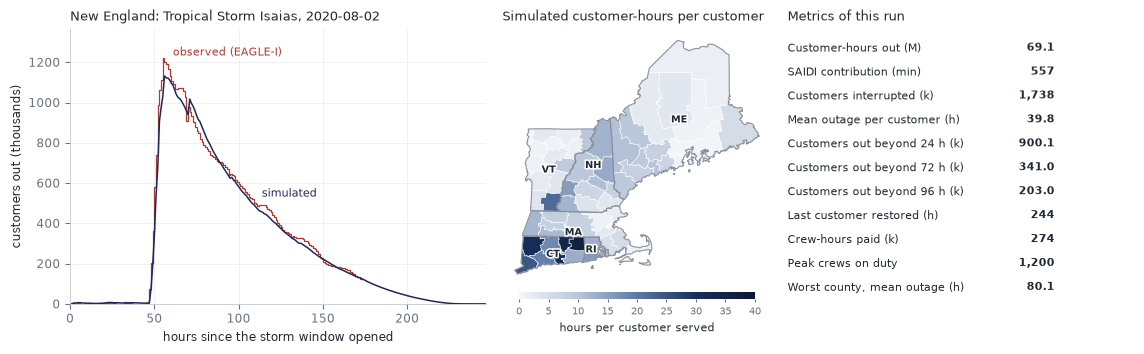

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display
from stormcrews import explore as E

fig = E.storm_figure(app.storm.result, with_card=True)
display(fig); plt.close(fig)

## From here to code

Each setting above is a field of a `Scenario`, and each run is one call to `Simulator.run`. The settings of the
*Real storm* tab, as code:

```python
from stormcrews import explore as E
settings = app.storm.settings()       # the dict behind the sliders
result = E.run_case(settings)         # the same run
result.metrics["saidi_min"]           # every metric is in result.metrics
```

The README of the repository explains the scenario keys, the rules and how to write your own.